# DoS attacks analysis
Submitted by: Fahad Waseem

In this notebook i load the attacks.csv that my detector made and i answer the
three questions from the project. for every question i show the code, a short
answer and a plot.

First i load the csv and take a quick look at what is inside it.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

#load the csv that the detector made
df = pd.read_csv("attacks.csv")

print("rows:", len(df))
print("columns:", list(df.columns))
df.head()

rows: 1995
columns: ['timestampp', 'attack_type', 'source_ip', 'length']


,timestampp,attack_type,source_ip,length
0,1.791644e+09,TCP-SYN PACKET,26.133.16.110,54
1,1.791644e+09,TCP-SYN PACKET,29.163.32.83,54
2,1.791644e+09,TCP-SYN PACKET,25.14.134.68,54
3,1.791644e+09,TCP-SYN PACKET,219.248.175.153,54
4,1.791644e+09,TCP-SYN PACKET,219.147.33.94,54


In [4]:
#renaming the attack types that are generated by the sniffndetect file for plots
nice_names = {
    "TCP-SYN PACKET": "SYN Flood",
    "TCP-SYNACK PACKET": "SYN-ACK Flood",
    "ICMP-PoD PACKET": "Ping of Death",
    "ICMP-SMURF PACKET": "Smurf",
}
df["attack_type"] = df["attack_type"].replace(nice_names)

## Question 1 - where are the suspect ips located?
i take the unique source ips from my csv and i skipped 127.0.0.1 because that is the
smurf attack using my own address. then i send them to ip-api.com in batches to
get the country and the location of each ip, and i show them on a world map.

In [5]:
import requests, time

#getting the unique source ips, skipping localhost because smurf uses my own ip
ips = df[df["source_ip"] != "127.0.0.1"]["source_ip"].unique().tolist()

#asking ip-api for the location, 100 ips at a time
results = []
for i in range(0, len(ips), 100):
    batch = ips[i:i + 100]
    r = requests.post("http://ip-api.com/batch", json=batch)
    results.extend(r.json())
    time.sleep(2)  #It gives ratelimit error so adding pause 

#keeping only the ones with a real location
geo = pd.DataFrame([x for x in results if x.get("status") == "success"])
print("located", len(geo), "ips")
geo[["query", "country", "lat", "lon"]].head()


located 1062 ips


,query,country,lat,lon
0,26.133.16.110,United States,39.9819,-82.904800
1,29.163.32.83,United States,39.9747,-82.894700
2,25.14.134.68,United Kingdom,51.5074,-0.127758
3,219.248.175.153,South Korea,37.5929,126.688000
4,219.147.33.94,China,37.8734,112.563000


In [6]:
import plotly.express as px

#putting every located ip as a dot on the world map
fig = px.scatter_geo(geo, lat="lat", lon="lon", hover_name="country",
                     title="Location of the suspect IPs")
fig.show()

### Answer
the suspect ips are spread across many countries around the world because i
generated random source ips. the map shows dots on every continent, and the top
countries by number of suspect ips are the United States, China and Japan.

## Question 2 - which attack generated the most packets?
every row in my csv is one detected attack packet so to find which attack sent
the most packets i just count the rows for each attack type. then i show it on a
bar chart.


In [5]:
#count how many packets each attack type sent
packet_counts = df["attack_type"].value_counts()
print(packet_counts)

attack_type
SYN Flood        571
SYN-ACK Flood    373
Smurf            333
Ping of Death    320
Name: count, dtype: int64


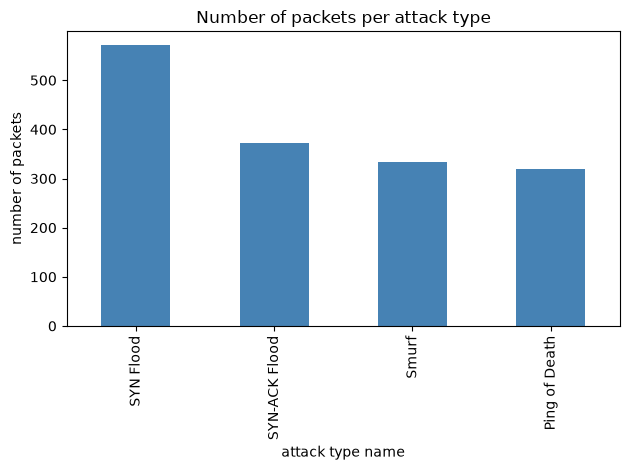

In [6]:
#making barchart of the number of packets for each attack
packet_counts.plot(kind="bar", color="steelblue")
plt.title("Number of packets per attack type")
plt.xlabel("attack type name")
plt.ylabel("number of packets")
plt.tight_layout()
plt.show()


### Answer
the attack that generated the most packets is the SYN flood, with the highest
number of packets out of the four attacks.

## Question 3 - which attack generated the most bytes, and bytes per second?
here i do not count packets, i add up the length (bytes) of all the packets for
each attack type. i also work out the bytes per second by dividing the total
bytes by how long each attack lasted using the timestamps. then i plot both.

attack_type
Ping of Death    1933440
SYN Flood          34754
SYN-ACK Flood      20142
Smurf              13986
Name: length, dtype: int64


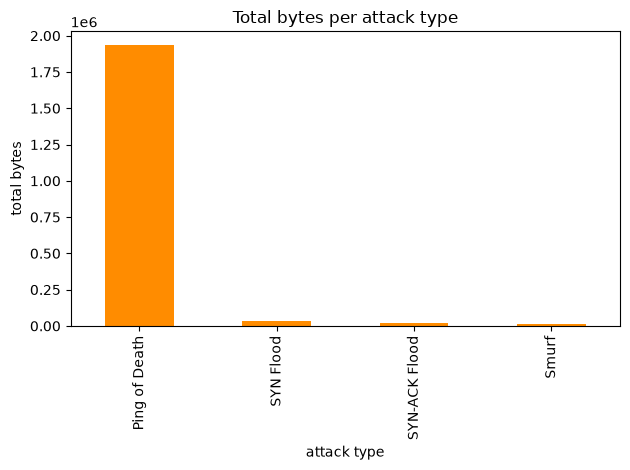

In [7]:
#adding the total bytes for each attack type
total_bytes = df.groupby("attack_type")["length"].sum()
print(total_bytes)

total_bytes.plot(kind="bar", color="darkorange")
plt.title("Total bytes per attack type")
plt.xlabel("attack type")
plt.ylabel("total bytes")
plt.tight_layout()
plt.show()

attack_type
Ping of Death    193661.121342
SYN Flood            32.383523
SYN-ACK Flood      2019.363109
Smurf              1402.599225
dtype: float64


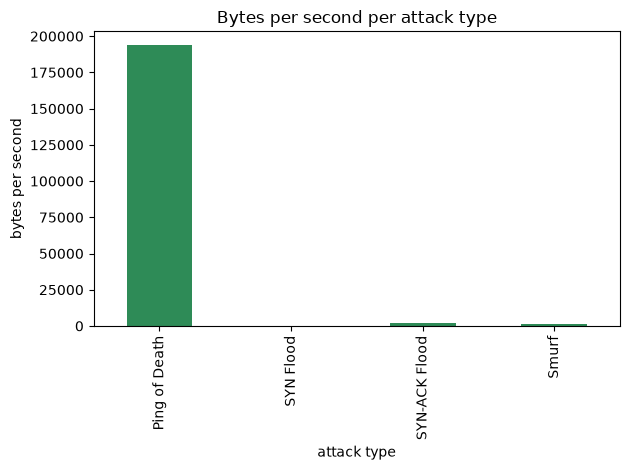

In [ ]:
#checking how long each attack lasted from the timestamps
duration = df.groupby("attack_type")["timestampp"].max() - df.groupby("attack_type")["timestampp"].min()

#the forumla to calculate is bytes per second = total bytes divided by how long the attack lasted
bytes_per_sec = total_bytes / duration
print(bytes_per_sec)

bytes_per_sec.plot(kind="bar", color="seagreen")
plt.title("Bytes per second per attack type")
plt.xlabel("attack type")
plt.ylabel("bytes per second")
plt.tight_layout()
plt.show()

### Answer
the attack with the most total bytes is Ping of death .
the attack with the most bytes per second is also the Ping of death attack .